In [15]:
import geopandas as gpd
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt

In [ ]:

gdf = gpd.read_file(r"data\raw\adr_gra_savivaldybes.json")

print("CRS before:", gdf.crs)  

gdf["centroid_proj"] = gdf.geometry.centroid

gdf_latlon = gdf.to_crs(epsg=4326)
gdf_latlon["centroid"] = gdf["centroid_proj"].to_crs(epsg=4326)


with io.open(r"C:\Users\user\Desktop\repos\igem-model\data\centersAps.csv", "w", encoding="utf-8") as f:
    for _, row in gdf_latlon.iterrows():
        f.write(row['SAV_PAV'] + "," + str(row['centroid'].y) + "," + str(row['centroid'].x) + "\n")
        print(f"Name: {row['SAV_PAV']}, Centroid: ({row['centroid'].y:.6f}, {row['centroid'].x:.6f})")


CRS before: EPSG:3346
Name: Alytaus apskr., Centroid: (54.221847, 24.125284)
Name: Vilniaus apskr., Centroid: (54.821211, 25.233581)
Name: Kauno apskr., Centroid: (55.075195, 23.886842)
Name: Klaipėdos apskr., Centroid: (55.724333, 21.478885)
Name: Marijampolės apskr., Centroid: (54.703999, 23.171699)
Name: Panevėžio apskr., Centroid: (55.917551, 24.801590)
Name: Šiaulių apskr., Centroid: (55.937979, 23.307560)
Name: Tauragės apskr., Centroid: (55.300665, 22.449120)
Name: Telšių apskr., Centroid: (56.000722, 22.163961)
Name: Utenos apskr., Centroid: (55.479085, 25.699177)


In [ ]:
import svgwrite

gdf = gpd.read_file(r"data\raw\adr_gra_savivaldybes.json")

gdf = gdf.to_crs(epsg=3346)

minx, miny, maxx, maxy = gdf.total_bounds
aspect = (maxx - minx) / (maxy - miny)
width = 1000
height = int(width / aspect)
scale_x = width / (maxx - minx)
scale_y = height / (maxy - miny)

dwg = svgwrite.Drawing("municipalities.svg", size=(width, height))

for _, row in gdf.iterrows():
    geom = row.geometry
    name = row["SAV_PAV"] 
    
    if geom.geom_type == "Polygon":
        polygons = [geom]
    elif geom.geom_type == "MultiPolygon":
        polygons = list(geom.geoms)
    else:
        continue

    for poly in polygons:

        points = [((x - minx) * scale_x, height - (y - miny) * scale_y) for x, y in poly.exterior.coords]
        name = name.replace(" ", "_").replace(".", "_")
        dwg.add(
            dwg.polygon(
                points=points,
                fill="none",
                stroke="black",
                id=name, 
            )
        )

# Save SVG
dwg.save()


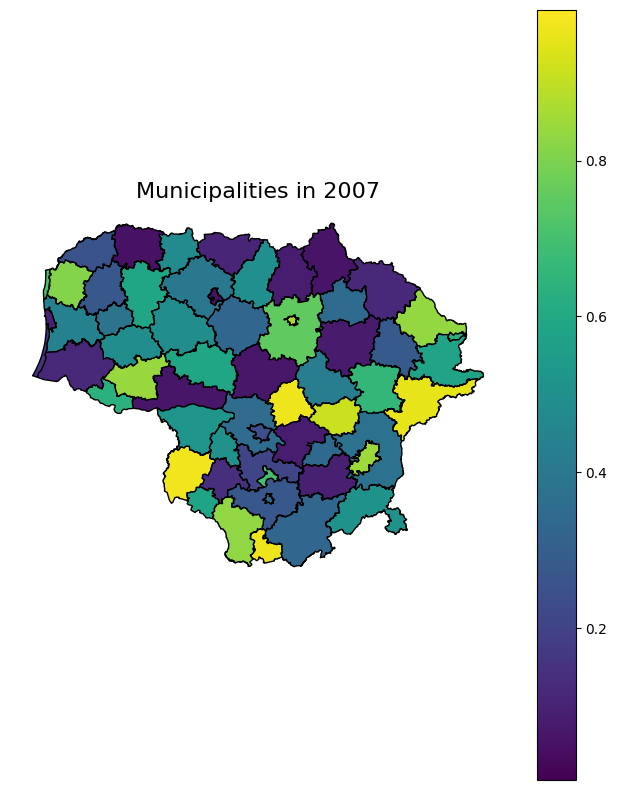

In [ ]:

from matplotlib.animation import FuncAnimation


gdf = gpd.read_file(r"data\raw\adr_gra_savivaldybes.json")

years = list(range(2004, 2008))
munis = gdf["SAV_PAV"].tolist()
data = pd.DataFrame({
    "SAV_PAV": munis,
})

for year in years:
    data[year] = np.random.rand(len(munis)) 

gdf = gdf.merge(data, on="SAV_PAV")

vmin = gdf[years].min().min()
vmax = gdf[years].max().max()


fig, ax = plt.subplots(figsize=(8, 10))
gdf.plot(
    column=years[0],
    ax=ax,
    cmap="viridis",
    edgecolor="black",
    vmin=vmin,
    vmax=vmax,
    legend=True  
)

ax.set_axis_off()



gdf.plot(ax=ax, color="white", edgecolor="black")

def update(year):

    ax.clear()
    ax.set_title(f"Municipalities in {year}", fontsize=16)
    ax.set_axis_off()
    gdf.plot(
        ax=ax,
        column=year,           
        cmap="viridis",         
        legend=False,
        vmin=vmin,
        vmax=vmax,
        edgecolor="black"
    )


ani = FuncAnimation(fig, update, frames=years, repeat=True)

ani.save("municipalities_animation.gif", writer="pillow", fps=1)
# ani.save("municipalities_animation.mp4", writer="ffmpeg", fps=2)

plt.show()
